In [9]:
from forest_fire_detection.load import SatelliteLoader
from forest_fire_detection.preprocessing import read_labels, egif_to_lonlat
import pandas as pd

loader = SatelliteLoader()

dataset = loader.load_by_quarter(2020, 1)

_, labels = read_labels("/home/marito/Documents/Projects/forest-fire-detection/data/processed/data_processed_2020-01-01_2023-12-31.csv")

labels_2020 = labels[(labels["Detectado"].dt.year == 2020)].sort_values(["Detectado", "Provincia", "Municipio"])

labels_2020

,NumeroParte,Comunidad,Provincia,Municipio,ComarcaIsla,EntidadMenor,NumeroMunicipiosAfectados,Cuadricula,Huso,CoordenadaX,...,NumeroPuntosInicioIncendio,Detectado,Extinguido,Causa,TipoInterfazAfectado,SuperficieArbolada,SuperficieNoArbolada,SuperficieTotalForestal,SuperficieAgricola,OtrasSuperficiesNoforestales
1,2020330002,ASTURIAS,ASTURIAS,CANGAS DEL NARCEA,NARCEA,LIMÉS,1,I06,29,703321.0,...,1,2020-01-01 02:49:00+00:00,2020-01-01 05:08:00+00:00,[400] Intencionado,,0.0,5.00,5.00,0.00,0.0
2,2020330003,ASTURIAS,ASTURIAS,CANGAS DEL NARCEA,NARCEA,ENTREVIÑAS,1,I06,29,703408.0,...,1,2020-01-01 09:08:00+00:00,2020-01-01 11:21:00+00:00,[400] Intencionado,,0.0,20.00,20.00,0.00,0.0
3,2020160001,CASTILLA-MANCHA,CUENCA,GARABALLA,SERRANIA BAJA,GARABALLA,1,C04,30,639155.0,...,1,2020-01-01 11:19:00+00:00,2020-01-01 12:45:00+00:00,[500] Desconocida,,0.0,0.01,0.01,0.00,0.0
4,2020260001,LA RIOJA,LA RIOJA,NIEVA DE CAMEROS,ORTIGOSA,NIEVA DE CAMEROS,1,E05,30,526092.0,...,1,2020-01-01 12:19:00+00:00,2020-01-01 14:10:00+00:00,[400] Intencionado,,0.0,0.06,0.06,0.00,0.0
5,2020240001,CASTILLA Y LEON,LEON,VILLABLINO,VILLABLINO-HUERGAS DE BABIA,EL VILLAR DE SANTIAGO,1,L08,30,235871.0,...,1,2020-01-01 12:55:00+00:00,2020-01-01 17:56:00+00:00,[400] Intencionado,,0.0,5.22,5.22,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8059,2020030087,C. VALENCIANA,ALICANTE,BENIFATO,LA MARINA BAIXA,BENIFATO,1,O04,30,741357.0,...,2,2020-12-29 21:22:00+00:00,2021-01-01 17:20:00+00:00,[400] Intencionado,,0.5,3.50,4.00,0.30,0.0
8060,2020030088,C. VALENCIANA,ALICANTE,SANTA POLA,EL BAIX VINALOPO,,1,E12,30,713301.0,...,1,2020-12-30 09:48:00+00:00,2020-12-31 08:30:00+00:00,"[294] Gamberradas, juegos de niños (quema de ...",1,0.0,6.10,6.10,0.00,0.0
8061,2020180119,ANDALUCIA,GRANADA,"GUAJARES, LOS",SIERRAS LITORALES,GUAJAR FONDON,1,F08,30,448270.0,...,3,2020-12-30 15:31:00+00:00,2020-12-30 20:00:00+00:00,[400] Intencionado,13,0.0,0.43,0.43,0.01,0.0
8062,2020500114,ARAGON,ZARAGOZA,CARENAS,COMUNIDAD DE CALATAYUD,CARENAS,1,A01,30,599995.0,...,1,2020-12-31 13:01:00+00:00,2020-12-31 16:31:00+00:00,[400] Intencionado,,0.0,0.68,0.68,4.28,0.0


In [10]:
timestamps_where_fire_detected = labels_2020[["Detectado", "Extinguido", "CoordenadaX", "CoordenadaY"]]

timestamps_where_fire_detected["Lapsus"] = timestamps_where_fire_detected["Extinguido"] - timestamps_where_fire_detected["Detectado"]
filtered = labels_2020[timestamps_where_fire_detected["Lapsus"] > pd.Timedelta(minutes=60)]

geo_filtered = egif_to_lonlat(filtered)

geo_filtered

,NumeroParte,Comunidad,Provincia,Municipio,ComarcaIsla,EntidadMenor,NumeroMunicipiosAfectados,Cuadricula,Huso,CoordenadaX,...,Extinguido,Causa,TipoInterfazAfectado,SuperficieArbolada,SuperficieNoArbolada,SuperficieTotalForestal,SuperficieAgricola,OtrasSuperficiesNoforestales,lon,lat
1,2020330002,ASTURIAS,ASTURIAS,CANGAS DEL NARCEA,NARCEA,LIMÉS,1,I06,29,703321.0,...,2020-01-01 05:08:00+00:00,[400] Intencionado,,0.0,5.00,5.00,0.00,0.0,-6.499163,43.157777
2,2020330003,ASTURIAS,ASTURIAS,CANGAS DEL NARCEA,NARCEA,ENTREVIÑAS,1,I06,29,703408.0,...,2020-01-01 11:21:00+00:00,[400] Intencionado,,0.0,20.00,20.00,0.00,0.0,-6.497782,43.165391
3,2020160001,CASTILLA-MANCHA,CUENCA,GARABALLA,SERRANIA BAJA,GARABALLA,1,C04,30,639155.0,...,2020-01-01 12:45:00+00:00,[500] Desconocida,,0.0,0.01,0.01,0.00,0.0,-1.374277,39.811715
4,2020260001,LA RIOJA,LA RIOJA,NIEVA DE CAMEROS,ORTIGOSA,NIEVA DE CAMEROS,1,E05,30,526092.0,...,2020-01-01 14:10:00+00:00,[400] Intencionado,,0.0,0.06,0.06,0.00,0.0,-2.683960,42.198913
5,2020240001,CASTILLA Y LEON,LEON,VILLABLINO,VILLABLINO-HUERGAS DE BABIA,EL VILLAR DE SANTIAGO,1,L08,30,235871.0,...,2020-01-01 17:56:00+00:00,[400] Intencionado,,0.0,5.22,5.22,0.00,0.0,-6.236268,42.921462
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8059,2020030087,C. VALENCIANA,ALICANTE,BENIFATO,LA MARINA BAIXA,BENIFATO,1,O04,30,741357.0,...,2021-01-01 17:20:00+00:00,[400] Intencionado,,0.5,3.50,4.00,0.30,0.0,-0.225642,38.673657
8060,2020030088,C. VALENCIANA,ALICANTE,SANTA POLA,EL BAIX VINALOPO,,1,E12,30,713301.0,...,2020-12-31 08:30:00+00:00,"[294] Gamberradas, juegos de niños (quema de ...",1,0.0,6.10,6.10,0.00,0.0,-0.563778,38.208853
8061,2020180119,ANDALUCIA,GRANADA,"GUAJARES, LOS",SIERRAS LITORALES,GUAJAR FONDON,1,F08,30,448270.0,...,2020-12-30 20:00:00+00:00,[400] Intencionado,13,0.0,0.43,0.43,0.01,0.0,-3.580158,36.837572
8062,2020500114,ARAGON,ZARAGOZA,CARENAS,COMUNIDAD DE CALATAYUD,CARENAS,1,A01,30,599995.0,...,2020-12-31 16:31:00+00:00,[400] Intencionado,,0.0,0.68,0.68,4.28,0.0,-1.805932,41.281784


In [11]:
import random
from time import time
from forest_fire_detection.viz.satellite import select_scene, plot_rgb, COMPOSITES
import numpy as np

CROP = (5, 5)

random.seed(31)

select = random.choice(geo_filtered.index)

selected_row = geo_filtered.loc[select]

lon, lat, detected = selected_row["lon"], selected_row["lat"], selected_row["Detectado"]

detected_round = (detected + pd.Timedelta(minutes=60)).floor("1h")

print(detected, detected_round)

satellite_image = dataset.sel(time=detected_round, method="nearest")

satellite_crop = satellite_image.sel(lon=slice(lon - CROP[0] / 2, lon + CROP[0] / 2),
                                     lat=slice(lat - CROP[1] / 2, lat + CROP[1] / 2))

satellite_crop

2020-01-14 10:55:00+00:00 2020-01-14 11:00:00+00:00


<xarray.Dataset> Size: 717kB
Dimensions:  (lat: 128, lon: 127)
Coordinates:
  * lat      (lat) float64 1kB 39.31 39.35 39.39 39.43 ... 44.21 44.25 44.29
  * lon      (lon) float64 1kB -0.1223 -0.08297 -0.04367 ... 4.751 4.79 4.83
    time     datetime64[ns] 8B 2020-01-14T11:00:00
Data variables:
    crs      |S1 1B dask.array<chunksize=(), meta=np.ndarray>
    IR10.8   (lat, lon) float32 65kB dask.array<chunksize=(128, 127), meta=np.ndarray>
    IR12.0   (lat, lon) float32 65kB dask.array<chunksize=(128, 127), meta=np.ndarray>
    IR13.4   (lat, lon) float32 65kB dask.array<chunksize=(128, 127), meta=np.ndarray>
    IR3.9    (lat, lon) float32 65kB dask.array<chunksize=(128, 127), meta=np.ndarray>
    IR8.7    (lat, lon) float32 65kB dask.array<chunksize=(128, 127), meta=np.ndarray>
    IR9.7    (lat, lon) float32 65kB dask.array<chunksize=(128, 127), meta=np.ndarray>
    NIR1.6   (lat, lon) float32 65kB dask.array<chunksize=(128, 127), meta=np.ndarray>
    VIS0.6   (lat, lon) float32 65kB dask.array<chunksize=(128, 127), meta=np.ndarray>
    VIS0.8   (lat, lon) float32 65kB dask.array<chunksize=(128, 127), meta=np.ndarray>
    WV6.2    (lat, lon) float32 65kB dask.array<chunksize=(128, 127), meta=np.ndarray>
    WV7.3    (lat, lon) float32 65kB dask.array<chunksize=(128, 127), meta=np.ndarray>
Attributes: (12/45)
    Conventions:                    CF-1.5
    ch01_cal:                       -1.064115040004e+00 2.086500078440e-02
    ch02_cal:                       -1.419263742864e+00 2.782870084047e-02
    ch03_cal:                       -1.185296142474e+00 2.324110083282e-02
    ch04_cal:                       -1.865920103496e-01 3.658666869601e-03
    ch05_cal:                       -4.242236706827e-01 8.318111189856e-03
    ...                             ...
    EPCT_roi:                       custom
    EPCT_sensing_start:             null
    EPCT_sensing_stop:              null
    EPCT_software_name:             DataTailor
    EPCT_software_version:          3.5.3
    EPCT_stretch_method:            null

(<Axes: xlabel='Longitud (°)', ylabel='Latitud (°)'>,
 <matplotlib.collections.QuadMesh at 0x752d4e1d25d0>)

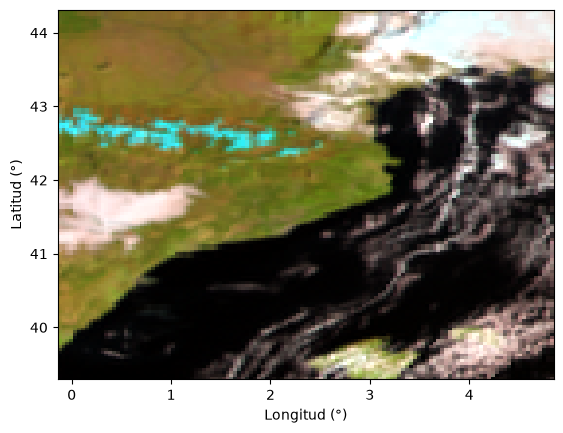

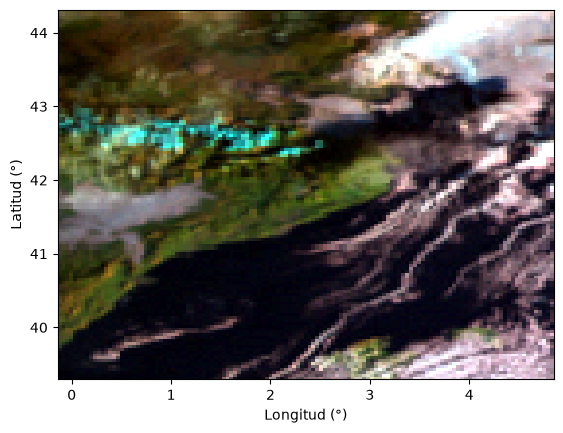

In [12]:
satellite_crop_early = dataset.sel(time=detected_round - pd.Timedelta(minutes=3*60), method="nearest")
satellite_crop_early = satellite_crop_early.sel(lon=slice(lon - CROP[0] / 2, lon + CROP[0] / 2),
                                               lat=slice(lat - CROP[1] / 2, lat + CROP[1] / 2))
plot_rgb(satellite_crop, channels=COMPOSITES["natural_color"])
plot_rgb(satellite_crop_early, channels=COMPOSITES["natural_color"])

In [13]:
from forest_fire_detection.load.dataset import build_training_dataset

training_dataset = build_training_dataset(raw_images=dataset,
                                          fire_data=geo_filtered,
                                          n_samples_without_fire=1600,
                                          detection_offset=pd.Timedelta(minutes=1*60)
                                          )

len(training_dataset)

2989

In [14]:
# Build a convolutional neural network for fire detection with torch

import torch
import torch.nn as nn

class FireDetectionCNN(nn.Module):
    def __init__(self):
        super(FireDetectionCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=11, out_channels=16, kernel_size=3, padding=1, stride=2)
        self.conv1_bn = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5, padding=2, stride=2)
        self.conv2_bn = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1, stride=2)
        self.conv3_bn = nn.BatchNorm2d(64)
        self.conv3_relu = nn.ReLU()
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc1_bn = nn.BatchNorm1d(128)
        self.fc2 = nn.Linear(128, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = torch.relu(self.conv1_bn(self.conv1(x)))
        x = torch.relu(self.conv2_bn(self.conv2(x)))
        x = torch.relu(self.conv3_bn(self.conv3(x)))
        x = torch.flatten(x, start_dim=1)
        x = torch.relu(self.fc1_bn(self.fc1(x)))
        x = self.sigmoid(self.fc2(x))
        return x

fire_detection_cnn = FireDetectionCNN()

print("Total number of parameters:", sum(p.numel() for p in fire_detection_cnn.parameters()))

Total number of parameters: 2130817


In [15]:
import torch
from torch.utils.data import random_split

n_samples = len(training_dataset)
train_size = int(0.75 * n_samples)
val_size = int(0.12 * n_samples)
test_size = n_samples - train_size - val_size

train_data, val_data, test_data = random_split(
    training_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42),
)

print(f"Train: {len(train_data)}")
print(f"Validación: {len(val_data)}")
print(f"Test: {len(test_data)}")

Train: 2241
Validación: 358
Test: 390


In [16]:
# Training loop with validation metrics

# Minimizing binary cross-entropy loss
from torch.utils.data import DataLoader

NUM_EPOCHS = 50
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
fire_detection_cnn = fire_detection_cnn.to(DEVICE)
OPTIMIZER = torch.optim.Adam(fire_detection_cnn.parameters(), lr=1e-3)
CRITERION = torch.nn.BCELoss()

train_loss_history = []
val_loss_history = []

print(f"Using device: {DEVICE}")
print("GPU seleccionada:", torch.cuda.get_device_name(DEVICE))
print("Número de GPUs disponibles:", torch.cuda.device_count())
print("Dispositivo actual:", torch.cuda.current_device())

best_val_loss = float('inf')
best_model_state = None

for epoch in range(NUM_EPOCHS):
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}")

    # Training step
    fire_detection_cnn.train()
    train_loss = 0.0
    for inputs, timestamps, targets in train_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).unsqueeze(1)
        OPTIMIZER.zero_grad()
        outputs = fire_detection_cnn(inputs)
        loss = CRITERION(outputs, targets)
        loss.backward()
        OPTIMIZER.step()
        train_loss += loss.item() * inputs.size(0)
    train_loss /= len(train_data)

    # Validation step every 10 epochs
    if epoch % 3 == 0:
        fire_detection_cnn.eval()
        val_loss = 0
        with torch.no_grad():
            for inputs, timestamps, targets in val_loader:
                inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).unsqueeze(1)
                outputs = fire_detection_cnn(inputs)
                loss = CRITERION(outputs, targets)
                val_loss += loss.item() * inputs.size(0)
        val_loss /= len(val_data)
        val_loss_history.append(val_loss)
        train_loss_history.append(train_loss)
        print(f"Validation Loss: {val_loss:.4f}")
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = fire_detection_cnn.state_dict()
    print(f"Training Loss: {train_loss:.4f}")


Using device: cuda
GPU seleccionada: NVIDIA GeForce RTX 5070 Ti
Número de GPUs disponibles: 1
Dispositivo actual: 0
Epoch 1/50
Validation Loss: 0.5720
Training Loss: 0.5814
Epoch 2/50
Training Loss: 0.4739
Epoch 3/50
Training Loss: 0.4035
Epoch 4/50
Validation Loss: 0.9504
Training Loss: 0.3399
Epoch 5/50
Training Loss: 0.3016
Epoch 6/50
Training Loss: 0.2657
Epoch 7/50
Validation Loss: 0.5647
Training Loss: 0.2131
Epoch 8/50
Training Loss: 0.1995
Epoch 9/50
Training Loss: 0.1308
Epoch 10/50
Validation Loss: 2.2225
Training Loss: 0.1043
Epoch 11/50
Training Loss: 0.0824
Epoch 12/50
Training Loss: 0.0563
Epoch 13/50
Validation Loss: 1.7646
Training Loss: 0.0511
Epoch 14/50
Training Loss: 0.0550
Epoch 15/50
Training Loss: 0.0392
Epoch 16/50
Validation Loss: 1.4446
Training Loss: 0.0320
Epoch 17/50
Training Loss: 0.0366
Epoch 18/50
Training Loss: 0.0292
Epoch 19/50
Validation Loss: 0.9485
Training Loss: 0.0469
Epoch 20/50
Training Loss: 0.0319
Epoch 21/50
Training Loss: 0.0319
Epoch 22/50

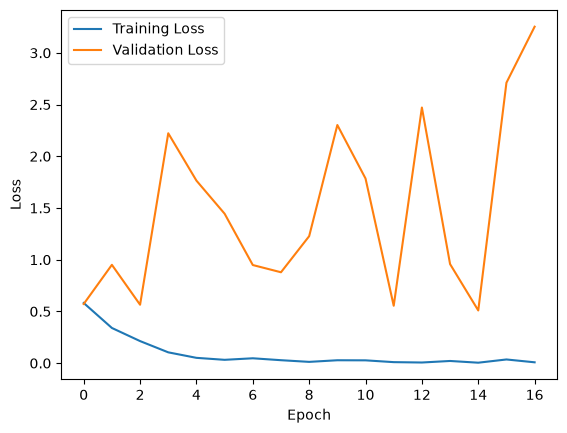

In [17]:
import matplotlib.pyplot as plt

plt.plot(train_loss_history, label="Training Loss")
plt.plot(val_loss_history, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [18]:
# Test loop

fire_detection_cnn.eval()

test_loss = 0
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

# test criterion is accuracy
TEST_CRITERION = torch.nn.BCELoss()  # Assuming binary classification with sigmoid output

outputs = []
targets_list = []

with torch.no_grad():
    for inputs, timestamps, targets in test_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).unsqueeze(1)
        batch_outputs = fire_detection_cnn(inputs)
        loss = TEST_CRITERION(batch_outputs, targets)
        test_loss += loss.item() * inputs.size(0)
        outputs.append(batch_outputs)
        targets_list.append(targets)
test_loss /= len(test_data)
print(f"Test Loss: {test_loss:.4f}")

outputs = torch.cat(outputs, dim=0)
targets = torch.cat(targets_list, dim=0)

Test Loss: 1.5347


In [19]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

def calculate_accuracy(outputs, targets):
    predicted = (outputs > 0.5).float()
    return accuracy_score(targets.cpu(), predicted.cpu())

def calculate_confusion_matrix(outputs, targets):
    predicted = (outputs > 0.5).float()
    return confusion_matrix(targets.cpu(), predicted.cpu())

print("Accuracy:", calculate_accuracy(outputs, targets))
print("Confusion Matrix:\n", calculate_confusion_matrix(outputs, targets))

Accuracy: 0.7
Confusion Matrix:
 [[200  24]
 [ 93  73]]


In [20]:
best_model_restored = FireDetectionCNN()
best_model_restored.load_state_dict(best_model_state)
best_model_restored = best_model_restored.to(DEVICE)

best_model_restored.eval()

outputs_restored = []
targets_restored = []

with torch.no_grad():
    for inputs, timestamps, targets in test_loader:
        inputs = inputs.to(DEVICE)
        outputs = best_model_restored(inputs)
        outputs_restored.append(outputs)
        targets_restored.append(targets.to(DEVICE).unsqueeze(1))

outputs_restored = torch.cat(outputs_restored, dim=0)
targets_restored = torch.cat(targets_restored, dim=0)

# Calculate accuracy
preds_restored = (outputs_restored > 0.5).float()
accuracy_restored = (preds_restored == targets_restored).float().mean()
print(f"Restored Model Accuracy: {accuracy_restored.item():.4f}")
# Calculate confusion matrix
from sklearn.metrics import confusion_matrix
cm_restored = confusion_matrix(targets_restored.cpu(), preds_restored.cpu())
print("Restored Model Confusion Matrix:")
print(cm_restored)


Restored Model Accuracy: 0.7000
Restored Model Confusion Matrix:
[[200  24]
 [ 93  73]]
